# Step 1: Load, clean, and check the project is viable

**Question:** among students who are doing well at the end of semester 1, are there enough who still dropped out for a model to learn from?

**Prediction moment:** end of semester 1. Only information the college has by then may be used, so no semester 2 columns appear anywhere in this project.

See `PLAN.md` for the full plan and the decisions made so far.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                       # fixed so every run gives the same result
DATA = Path("data.csv")

pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1.1 Load the data

The file separates values with `;` instead of commas, so we tell pandas. We also strip stray whitespace from the column names, because one of them hides a tab character that would break lookups later. The original `data.csv` is never modified.

In [2]:
raw = pd.read_csv(DATA, sep=";")
raw.columns = raw.columns.str.strip()   # one column name hides a tab character
print(raw.shape)
raw.head(3)

(4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


## 1.2 Basic health checks

Before trusting any data we check for **missing values** (blank cells), **duplicate rows** (the same student twice, which would quietly inflate results) and how the three outcomes are split.

In [3]:
print("missing values :", int(raw.isna().sum().sum()))
print("duplicate rows :", int(raw.duplicated().sum()))
raw["Target"].value_counts()

missing values : 0
duplicate rows : 0


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

## 1.3 Keep only students whose outcome is known

Students marked **Enrolled** are still studying, so we don't yet know whether they will drop out. Training on them would mean guessing the answer, so they are set aside. The remaining students become a yes/no target: `dropout` = 1 if they dropped out, 0 if they graduated.

In [4]:
df = raw[raw["Target"] != "Enrolled"].copy()
df["dropout"] = (df["Target"] == "Dropout").astype(int)   # 1 = dropped out, 0 = graduated

print("students kept :", len(df))
print(f"dropout rate  : {df['dropout'].mean():.1%}")

students kept : 3630
dropout rate  : 39.1%


## 1.4 Build the two measures behind "doing well"

- **Pass rate** = courses approved / courses enrolled, for semester 1. It tells us how much of their workload the student actually cleared.
- **Grade** = the semester 1 average grade (scale 0 to 20, pass mark 10).

Two traps in this data, handled on purpose:
- A student enrolled in **0 courses** has no pass rate (dividing by zero), so it stays *missing* rather than being faked as 0.
- A grade of **0 does not mean the student scored zero**. It means they passed nothing, so no average exists. We mark it missing so it cannot pull averages down.

In [5]:
ENR = "Curricular units 1st sem (enrolled)"
APP = "Curricular units 1st sem (approved)"
GRD = "Curricular units 1st sem (grade)"

no_courses = df[ENR] == 0
print("enrolled in 0 courses in semester 1:", int(no_courses.sum()))

# pass rate is undefined when nothing was enrolled, so keep it missing instead of inventing a 0
df["pass_rate"] = (df[APP] / df[ENR]).where(~no_courses)

# a grade of 0 means "passed nothing" (no average exists), so mark it missing
df["grade"] = df[GRD].where(df[GRD] > 0)
print("students with no grade (passed nothing):", int(df["grade"].isna().sum()))

df[["pass_rate", "grade"]].describe().round(2)

enrolled in 0 courses in semester 1: 152
students with no grade (passed nothing): 647


,pass_rate,grade
count,3478.00,2983.00
mean,0.73,12.82
std,0.36,1.35
min,0.00,9.80
25%,0.60,11.84
50%,0.88,12.75
75%,1.00,13.71
max,1.00,18.88


## 1.5 Look before deciding

Two histograms (bar charts of how many students fall into each value range), split by outcome. They show how differently graduates and dropouts look on the two measures we are about to use.

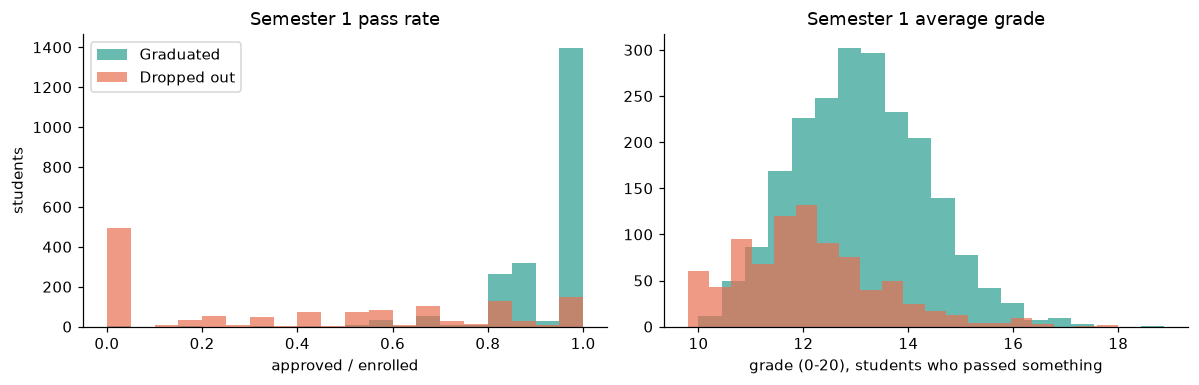

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for label, name, colour in [(0, "Graduated", "#2a9d8f"), (1, "Dropped out", "#e76f51")]:
    sub = df[df["dropout"] == label]
    ax[0].hist(sub["pass_rate"].dropna(), bins=20, alpha=0.7, label=name, color=colour)
    ax[1].hist(sub["grade"].dropna(), bins=20, alpha=0.7, label=name, color=colour)
ax[0].set(title="Semester 1 pass rate", xlabel="approved / enrolled", ylabel="students")
ax[1].set(title="Semester 1 average grade", xlabel="grade (0-20), students who passed something")
ax[0].legend()
plt.tight_layout()
plt.show()

## 1.6 The "doing well" rule, and how sensitive it is to the thresholds

A student counts as **doing well** if both hold:
1. **pass rate** is at least some minimum, and
2. **average grade** passes a grade rule (we try three: none, a fixed grade of 12, or at least the median grade of their own course).

We don't yet know the right thresholds, so instead of guessing we try several and watch how the group changes. This is a **sensitivity table**: it shows whether our conclusions depend on one lucky number.

The two things to read off it are the **size of the group** and the **number of dropouts inside it**. Dropouts are the "positive" cases the model must learn from, and too few of them makes any model unreliable.

> Caution: the course medians here use the whole dataset, which is fine for *counting*. The final labelling computes them from the training data only (step 2), or the test set would leak into the label.

In [7]:
course_median = df.groupby("Course")["grade"].transform("median")


def doing_well(pass_min, grade_rule):
    ok = df["pass_rate"] >= pass_min          # a missing pass rate compares as False
    if grade_rule == "course median":
        ok &= df["grade"] >= course_median
    elif grade_rule == "grade >= 12":
        ok &= df["grade"] >= 12
    return ok


rows = []
for rule in ["no grade rule", "grade >= 12", "course median"]:
    for x in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
        m = doing_well(x, rule)
        rows.append({
            "grade rule": rule,
            "min pass rate": x,
            "doing well": int(m.sum()),
            "dropouts": int(df.loc[m, "dropout"].sum()),
            "dropout rate": round(df.loc[m, "dropout"].mean(), 3),
        })
sens = pd.DataFrame(rows)
sens

,grade rule,min pass rate,doing well,dropouts,dropout rate
0,no grade rule,0.5,2751,625,0.227
1,no grade rule,0.6,2646,531,0.201
2,no grade rule,0.7,2394,363,0.152
3,no grade rule,0.8,2332,320,0.137
4,no grade rule,0.9,1585,159,0.100
5,no grade rule,1.0,1546,151,0.098
6,grade >= 12,0.5,2105,369,0.175
7,grade >= 12,0.6,2049,320,0.156
8,grade >= 12,0.7,1923,243,0.126
9,grade >= 12,0.8,1880,214,0.114


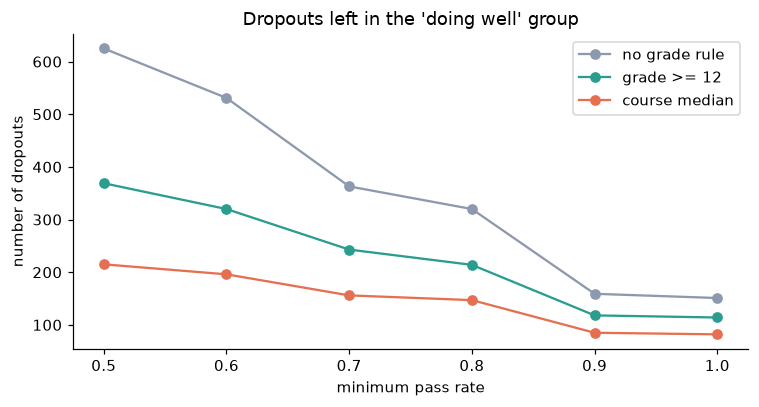

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.8))
for rule, colour in [("no grade rule", "#8d99ae"), ("grade >= 12", "#2a9d8f"), ("course median", "#e76f51")]:
    s = sens[sens["grade rule"] == rule]
    ax.plot(s["min pass rate"], s["dropouts"], marker="o", label=rule, color=colour)
ax.set(title="Dropouts left in the 'doing well' group",
       xlabel="minimum pass rate", ylabel="number of dropouts")
ax.legend()
plt.tight_layout()
plt.show()

## 1.7 Small courses

A per-course cut-off needs enough students in each course to be trustworthy. Here are the courses with the fewest graded students. A "typical grade" built on a handful of students is unreliable, so these will need to be merged or excluded later.

In [9]:
by_course = df.groupby("Course").agg(
    students=("dropout", "size"),
    graded=("grade", "count"),
    dropout_rate=("dropout", "mean"),
).round(2)
by_course.sort_values("graded").head(6)

,students,graded,dropout_rate
Course,,,
33,9,6,0.89
171,178,26,0.46
9556,69,59,0.48
9119,106,61,0.87
9130,120,90,0.65
9853,142,124,0.60


## Step 1 findings

- **3,630 students** have a known outcome, and **39.1%** of them dropped out.
- The "doing well" group is large (about 1,000 to 2,700 students depending on the rule), but its **dropout rate falls to roughly 8% to 15%** for the stricter settings. That is the rare event the model must find.
- Pass rates are **lumpy**: 1,546 students passed everything, and the rest cluster at 0.80, 0.83, 0.86 and 0.88 (5/6, 6/7, 7/8 courses). So moving the threshold from 0.7 to 0.8 barely changes the group (2,394 to 2,332 with no grade rule), but moving from 0.8 to 0.9 removes about 750 students.
- **Data-quality issue:** all 152 students enrolled in 0 courses in semester 1 belong to course 171 (Animation and Multimedia Design). They also have 0 enrolled in semester 2, yet 49% of them graduated. Their academic columns look like missing data stored as zeros. They fall out of the "doing well" group automatically, because their pass rate is missing.
- Courses 33 and 171 are too small to support their own grade cut-off.

**Decision:** doing well = pass rate of at least 0.8 **and** a grade at or above the median of the student's own course.

# Step 2: Split first, then define "doing well" from training data only

**Why this order:** anything computed from the data (a median, an average, a threshold) can carry information from students the model is supposed to *not* have seen. That is **data leakage**, and it makes results look better than they will be in real life.

The rule for the rest of the project: **split first, then compute everything from the training students only.**

## 2.1 Split the students into train and test

- **Train (80%)** is what we learn from and explore.
- **Test (20%)** is locked away and used once, at the very end, to see how the model does on students it has never seen. It is like keeping an exam paper sealed until exam day.

**Stratified** means both parts keep the same mix of outcomes. Without it, a small test set could by chance contain almost no dropouts. The `random_state` (the seed) makes the split identical every time you run it.

In [10]:
from sklearn.model_selection import train_test_split

# Stratify on the outcome AND on "passed at least 80% of courses". Both are facts about one
# student only, so using them here leaks nothing from other students.
strata = df["dropout"].astype(str) + "_" + (df["pass_rate"] >= 0.8).astype(str)

train, test = train_test_split(df, test_size=0.2, stratify=strata, random_state=SEED)

print("train:", len(train), "| test:", len(test))
print(f"dropout rate   train {train['dropout'].mean():.1%} | test {test['dropout'].mean():.1%}")

train: 2904 | test: 726
dropout rate   train 39.2% | test 39.1%


## 2.2 Grade cut-offs, from the training students only

The cut-off for each course is the **median grade** of its *training* students. A median is the middle value, so half of a course's students are above it. This is the step where leakage would happen if we used all students, because the cut-off would then contain information from the test set.

Courses with fewer than 30 graded training students are too small for a reliable median, so they use the median of all training students instead.

In [11]:
MIN_GRADED = 30          # courses with fewer graded training students use the pooled median

graded_per_course = train.groupby("Course")["grade"].count()
pooled_cutoff = train["grade"].median()
course_cutoff = train.groupby("Course")["grade"].median()
course_cutoff = course_cutoff.where(graded_per_course >= MIN_GRADED, pooled_cutoff)

print(f"pooled median (training only): {pooled_cutoff:.2f}")
print("courses using the pooled median:", sorted(course_cutoff[graded_per_course < MIN_GRADED].index.tolist()))
course_cutoff.round(2).sort_values()

pooled median (training only): 12.75
courses using the pooled median: [33, 171]


Course
9991    11.60
9147    11.75
9119    12.12
9254    12.17
9238    12.20
9130    12.29
8014    12.40
9556    12.43
9670    12.63
9853    12.67
9003    12.71
171     12.75
33      12.75
9773    13.00
9070    13.00
9500    13.39
9085    13.50
Name: grade, dtype: float64

## 2.3 Apply the rule to both splits

The rule is the same for everyone: **pass rate of at least 0.8, and a grade at or above the cut-off for the student's own course.** The cut-offs come from the training table above, and test students are simply looked up in it. Students with a missing pass rate or grade fail the rule automatically.

Then we keep the "doing well" students of each split. These two tables are what the rest of the project works with.

In [12]:
def label_doing_well(frame):
    cutoff = frame["Course"].map(course_cutoff).fillna(pooled_cutoff)
    return (frame["pass_rate"] >= 0.8) & (frame["grade"] >= cutoff)   # missing values count as False


train = train.assign(doing_well=label_doing_well(train))
test = test.assign(doing_well=label_doing_well(test))

train_dw = train[train["doing_well"]].copy()
test_dw = test[test["doing_well"]].copy()

summary = pd.DataFrame({
    "students": [len(train), len(test)],
    "doing well": [len(train_dw), len(test_dw)],
    "dropouts among doing well": [int(train_dw["dropout"].sum()), int(test_dw["dropout"].sum())],
}, index=["train", "test"])
summary["dropout rate (doing well)"] = (summary["dropouts among doing well"] / summary["doing well"]).round(3)
summary

,students,doing well,dropouts among doing well,dropout rate (doing well)
train,2904,1090,117,0.107
test,726,260,34,0.131


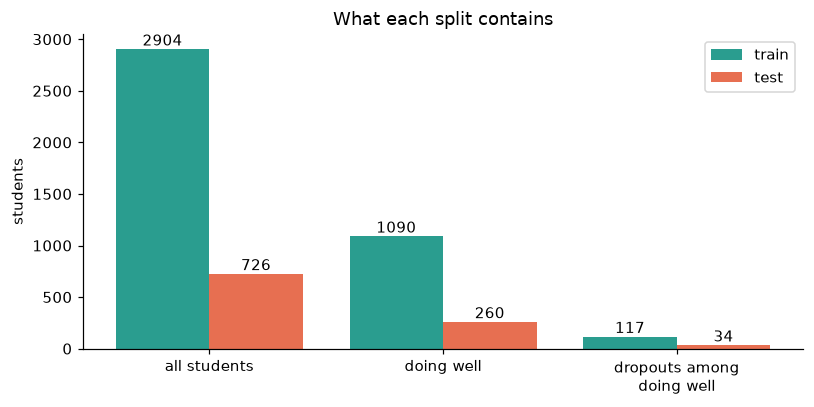

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(3)
labels = ["all students", "doing well", "dropouts among\ndoing well"]
bars_train = ax.bar(x - 0.2, [len(train), train["doing_well"].sum(), train_dw["dropout"].sum()],
                    0.4, label="train", color="#2a9d8f")
bars_test = ax.bar(x + 0.2, [len(test), test["doing_well"].sum(), test_dw["dropout"].sum()],
                   0.4, label="test", color="#e76f51")
ax.bar_label(bars_train)
ax.bar_label(bars_test)
ax.set_xticks(x, labels)
ax.set(title="What each split contains", ylabel="students")
ax.legend()
plt.tight_layout()
plt.show()

## Step 2 findings

- The split gave **2,904 train** and **726 test** students, with almost identical dropout rates (39.2% and 39.1%), so stratifying worked.
- With cut-offs taken from training students only, **1,350 students are doing well**: 1,090 in train and 260 in test. This is close to the 1,357 we counted on the full data in step 1, which is reassuring.
- **Dropouts among doing-well students: 117 in train and only 34 in test.** The dropout rate is 10.7% in train and 13.1% in test.
- The gap between 10.7% and 13.1% is mostly chance. With only 260 test students, a handful of extra dropouts moves the rate by a couple of points. This is the real limit of the project: **34 test positives is too few to trust a single test score**, so from step 5 onward we will judge models with repeated cross-validation on the training data and treat the test set as one final check.
- Courses 33 and 171 use the pooled median (12.75), as planned.

# Step 3: Explore the training group

Only the **doing-well training students** (`train_dw`) are used here. The test students stay untouched.

The dashed grey lines show the overall dropout rate in this group, so you can see which factors sit above or below it.

In [14]:
binary_cols = ["Debtor", "Tuition fees up to date", "Scholarship holder", "Displaced",
               "Gender", "International", "Educational special needs", "Daytime/evening attendance"]
rows = []
for col in binary_cols:
    for value, g in train_dw.groupby(col):
        rows.append({"feature": col, "value": value, "students": len(g),
                     "dropout rate": round(g["dropout"].mean(), 3)})
pd.DataFrame(rows).pivot(index="feature", columns="value", values=["students", "dropout rate"])

students         dropout rate       
value                             0       1            0      1
feature                                                        
Daytime/evening attendance    116.0   974.0        0.112  0.107
Debtor                       1030.0    60.0        0.089  0.417
Displaced                     462.0   628.0        0.106  0.108
Educational special needs    1081.0     9.0        0.106  0.222
Gender                        825.0   265.0        0.092  0.155
International                1064.0    26.0        0.108  0.077
Scholarship holder            682.0   408.0        0.133  0.064
Tuition fees up to date        39.0  1051.0        0.667  0.087

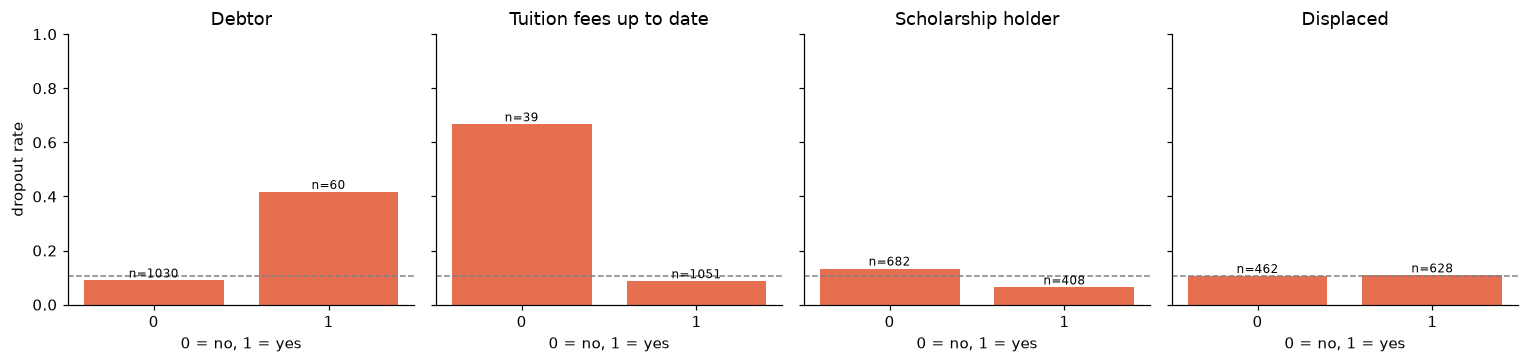

In [15]:
overall = train_dw["dropout"].mean()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, ["Debtor", "Tuition fees up to date", "Scholarship holder", "Displaced"]):
    g = train_dw.groupby(col)["dropout"].agg(["mean", "size"])
    bars = ax.bar(g.index.astype(str), g["mean"], color="#e76f51")
    ax.bar_label(bars, labels=[f"n={n}" for n in g["size"]], fontsize=8)
    ax.axhline(overall, ls="--", c="grey", lw=1)
    ax.set(title=col, ylim=(0, 1), xlabel="0 = no, 1 = yes")
axes[0].set_ylabel("dropout rate")
plt.tight_layout()
plt.show()

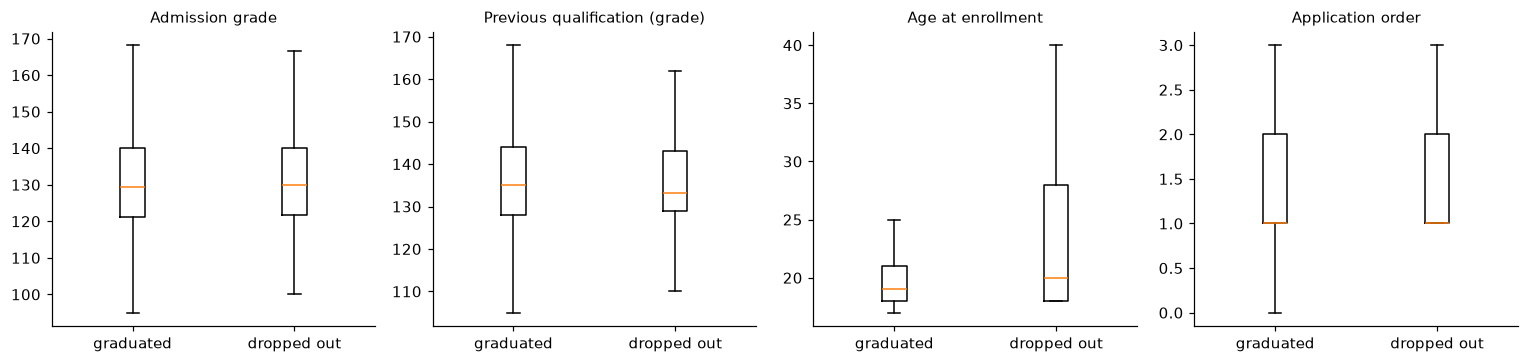

In [16]:
num_cols = ["Admission grade", "Previous qualification (grade)", "Age at enrollment", "Application order"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, col in zip(axes, num_cols):
    data = [train_dw.loc[train_dw["dropout"] == k, col] for k in (0, 1)]
    ax.boxplot(data, tick_labels=["graduated", "dropped out"], showfliers=False)
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.show()

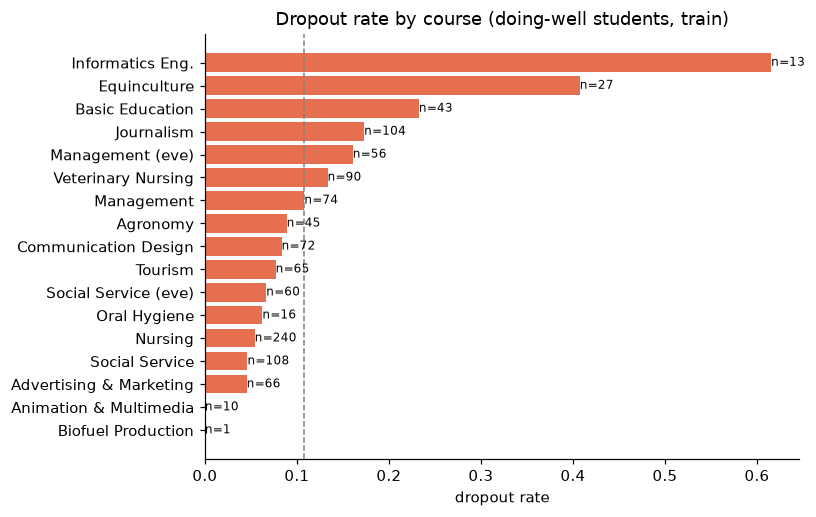

In [17]:
COURSE_NAMES = {33: "Biofuel Production", 171: "Animation & Multimedia", 8014: "Social Service (eve)",
                9003: "Agronomy", 9070: "Communication Design", 9085: "Veterinary Nursing",
                9119: "Informatics Eng.", 9130: "Equinculture", 9147: "Management",
                9238: "Social Service", 9254: "Tourism", 9500: "Nursing", 9556: "Oral Hygiene",
                9670: "Advertising & Marketing", 9773: "Journalism", 9853: "Basic Education",
                9991: "Management (eve)"}

by_course = train_dw.groupby("Course")["dropout"].agg(["mean", "size"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(7.5, 4.8))
bars = ax.barh([COURSE_NAMES[c] for c in by_course.index], by_course["mean"], color="#e76f51")
ax.bar_label(bars, labels=[f"n={n}" for n in by_course["size"]], fontsize=8)
ax.axvline(overall, ls="--", c="grey", lw=1)
ax.set(title="Dropout rate by course (doing-well students, train)", xlabel="dropout rate")
plt.tight_layout()
plt.show()

# Step 4: Preprocessing pipeline and baseline models

**Preprocessing** turns columns into numbers a model can use:
- Category codes (course, parents' jobs, ...) become one-hot columns (one yes/no column per category). Rare categories (fewer than 15 students) are merged into one "other" group.
- Numeric columns are standardised (centred and scaled) so that no column dominates by size alone.

Both are wrapped in a **pipeline**, so each cross-validation fold learns its encoding and scaling from its own training part only. This prevents leakage.

**Scoring:** the dropout class is rare (about 11%), so accuracy would be misleading. We use **average precision (AP)**, which summarises the precision-recall trade-off, and **ROC AUC**, the chance that a random dropout is ranked riskier than a random non-dropout. A model that guesses scores an AP equal to the dropout rate and an AUC of 0.5.

Cross-validation here is 5 folds repeated 5 times (25 fits), because there are only 117 positives in training.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

MONEY = ["Debtor", "Tuition fees up to date", "Scholarship holder"]
ENTRY = ["Application mode", "Application order", "Course", "Previous qualification",
         "Previous qualification (grade)", "Admission grade"]
FAMILY = ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
PERSONAL = ["Age at enrollment", "Displaced"]
SEM1 = ["Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
        "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
        "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)"]
ECON = ["Unemployment rate", "Inflation rate", "GDP"]
SENSITIVE = ["Gender", "Marital status", "Nacionality", "International", "Educational special needs"]

CATEGORICAL = ["Application mode", "Course", "Previous qualification", "Marital status", "Nacionality"] + FAMILY

EXTERNAL = MONEY + ENTRY + FAMILY + PERSONAL
feature_sets = {
    "money only": MONEY,
    "external only": EXTERNAL,
    "external + semester 1": EXTERNAL + SEM1,
    "external + economy": EXTERNAL + ECON,
    "external + sensitive": EXTERNAL + SENSITIVE,
    "everything": EXTERNAL + SEM1 + ECON + SENSITIVE,
}

y_train = train_dw["dropout"]
y_test = test_dw["dropout"]
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)


def make_pipeline(cols, estimator):
    cat = [c for c in cols if c in CATEGORICAL]
    num = [c for c in cols if c not in CATEGORICAL]
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=15, sparse_output=False), cat),
        ("num", StandardScaler(), num),
    ])
    return Pipeline([("prep", prep), ("model", estimator)])


def cv_scores(cols, estimator):
    res = cross_validate(make_pipeline(cols, estimator), train_dw[cols], y_train, cv=CV,
                         scoring={"ap": "average_precision", "auc": "roc_auc"}, n_jobs=1)
    return {"AP": res["test_ap"].mean(), "AP std": res["test_ap"].std(),
            "AUC": res["test_auc"].mean(), "AUC std": res["test_auc"].std()}


def logreg(C=0.1):
    return LogisticRegression(C=C, class_weight="balanced", max_iter=3000)


print(f"dropout rate in training group (the 'guessing' AP): {y_train.mean():.3f}")
baseline = pd.DataFrame({"dummy (always guesses the rate)": cv_scores(EXTERNAL, DummyClassifier(strategy="prior"))}).T
baseline

dropout rate in training group (the 'guessing' AP): 0.107


,AP,AP std,AUC,AUC std
dummy (always guesses the rate),0.107339,0.002247,0.5,0.0


## Which columns should the model see?

The plan listed several column groups to test rather than assume. Here is the same logistic regression with each group added in turn. "Sensitive" means gender, marital status, nationality, international and special needs.

In [19]:
fs_results = pd.DataFrame({name: cv_scores(cols, logreg()) for name, cols in feature_sets.items()}).T
fs_results.round(3)

,AP,AP std,AUC,AUC std
money only,0.320,0.062,0.683,0.061
external only,0.380,0.062,0.689,0.064
external + semester 1,0.424,0.071,0.717,0.059
external + economy,0.378,0.060,0.699,0.060
external + sensitive,0.384,0.059,0.686,0.065
everything,0.417,0.078,0.727,0.056


**Reading the table:**
- Guessing scores an AP of 0.107. Every real set beats it by a wide margin, so there is a signal.
- Adding the **economy** columns changes nothing (0.378 against 0.380), so they are left out.
- Adding the **sensitive** columns changes nothing useful either (AP +0.004, AUC slightly lower), so leaving them out costs no accuracy.
- Adding **semester 1 performance** helps a little (AP 0.380 to 0.424), though the fold-to-fold spread is about 0.06, so treat that gain as modest.

**Chosen inputs for the rest of the project: money, entry route, family background, age, displaced, and the semester 1 columns.** No economy columns and no sensitive columns.

# Step 5: Stronger models

Same cross-validation splits, same chosen columns, so scores are directly comparable. Settings are chosen from a short list, not an exhaustive search, because with only 117 positives an extensive search would mostly fit noise.

In [20]:
FINAL_COLS = EXTERNAL + SEM1

candidates = {
    "logistic, C=0.01": logreg(0.01),
    "logistic, C=0.03": logreg(0.03),
    "logistic, C=0.1": logreg(0.1),
    "logistic, C=0.3": logreg(0.3),
    "random forest, leaf 5": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
        random_state=SEED, n_jobs=1),
    "random forest, leaf 15": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=15, class_weight="balanced_subsample",
        random_state=SEED, n_jobs=1),
    "gradient boosting": HistGradientBoostingClassifier(
        max_depth=3, learning_rate=0.05, max_iter=150, l2_regularization=1.0,
        class_weight="balanced", random_state=SEED),
}
model_results = pd.DataFrame({name: cv_scores(FINAL_COLS, est) for name, est in candidates.items()}).T
model_results.round(3).sort_values("AP", ascending=False)

,AP,AP std,AUC,AUC std
"logistic, C=0.1",0.424,0.071,0.717,0.059
"logistic, C=0.3",0.422,0.070,0.715,0.061
"logistic, C=0.03",0.415,0.077,0.718,0.057
"logistic, C=0.01",0.406,0.082,0.719,0.055
"random forest, leaf 5",0.395,0.067,0.721,0.061
gradient boosting,0.382,0.075,0.691,0.063
"random forest, leaf 15",0.355,0.071,0.703,0.057


# Step 6: Evaluation on the test students

The best model by cross-validated AP is refitted on all training students and scored **once** on the test students. With only 34 test dropouts, a bootstrap interval (re-scoring many resampled copies of the test set) shows how much that single number could move by chance.

In [21]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

best_name = model_results["AP"].astype(float).idxmax()
print("best model by cross-validated AP:", best_name)

final_model = make_pipeline(FINAL_COLS, candidates[best_name]).fit(train_dw[FINAL_COLS], y_train)
test_score = final_model.predict_proba(test_dw[FINAL_COLS])[:, 1]

ap = average_precision_score(y_test, test_score)
auc = roc_auc_score(y_test, test_score)

rng = np.random.default_rng(SEED)
boot_ap, boot_auc = [], []
for _ in range(1000):
    idx = rng.integers(0, len(y_test), len(y_test))
    yb = y_test.to_numpy()[idx]
    if yb.sum() == 0:
        continue
    boot_ap.append(average_precision_score(yb, test_score[idx]))
    boot_auc.append(roc_auc_score(yb, test_score[idx]))

print(f"test dropout rate (guessing AP): {y_test.mean():.3f}")
print(f"test AP : {ap:.3f}   95% interval {np.percentile(boot_ap, 2.5):.3f} to {np.percentile(boot_ap, 97.5):.3f}")
print(f"test AUC: {auc:.3f}   95% interval {np.percentile(boot_auc, 2.5):.3f} to {np.percentile(boot_auc, 97.5):.3f}")

best model by cross-validated AP: logistic, C=0.1


test dropout rate (guessing AP): 0.131
test AP : 0.474   95% interval 0.322 to 0.631
test AUC: 0.726   95% interval 0.616 to 0.826


In [22]:
order = np.argsort(-test_score)
y_sorted = y_test.to_numpy()[order]
rows = []
for frac in (0.1, 0.2, 0.3, 0.5):
    k = int(np.ceil(frac * len(y_sorted)))
    caught = int(y_sorted[:k].sum())
    rows.append({"students flagged": f"top {int(frac*100)}% ({k})", "dropouts caught": caught,
                 "share of all dropouts caught": round(caught / y_sorted.sum(), 2),
                 "precision": round(caught / k, 2),
                 "lift vs random": round((caught / k) / y_test.mean(), 2)})
pd.DataFrame(rows)

,students flagged,dropouts caught,share of all dropouts caught,precision,lift vs random
0,top 10% (26),12,0.35,0.46,3.53
1,top 20% (52),19,0.56,0.37,2.79
2,top 30% (78),21,0.62,0.27,2.06
3,top 50% (130),25,0.74,0.19,1.47


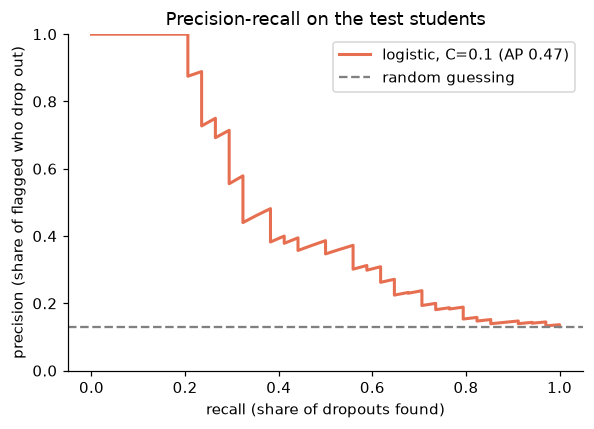

In [23]:
prec, rec, _ = precision_recall_curve(y_test, test_score)
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(rec, prec, color="#e76f51", lw=2, label=f"{best_name} (AP {ap:.2f})")
ax.axhline(y_test.mean(), ls="--", c="grey", label="random guessing")
ax.set(title="Precision-recall on the test students", xlabel="recall (share of dropouts found)",
       ylabel="precision (share of flagged who drop out)", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

# Step 7: Which factors matter, and is it fair?

**Permutation importance** shuffles one column at a time on the test students and measures how much the score drops. A large drop means the model relied on that column. It is computed per original column, and with 34 positives the bars are noisy, so read the ranking loosely.

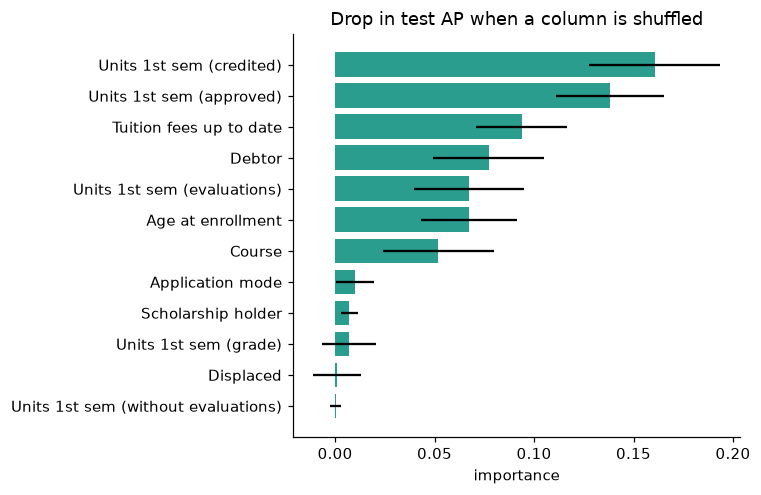

,mean,std
Curricular units 1st sem (credited),0.1606,0.0329
Curricular units 1st sem (approved),0.1382,0.0271
Tuition fees up to date,0.0938,0.0228
Debtor,0.0771,0.0278
Curricular units 1st sem (evaluations),0.0673,0.0278
Age at enrollment,0.0673,0.0240
Course,0.0518,0.0280
Application mode,0.0100,0.0096
Scholarship holder,0.0072,0.0043
Curricular units 1st sem (grade),0.0070,0.0135


In [24]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(final_model, test_dw[FINAL_COLS], y_test, scoring="average_precision",
                             n_repeats=30, random_state=SEED, n_jobs=1)
imp_df = pd.DataFrame({"mean": imp.importances_mean, "std": imp.importances_std},
                      index=FINAL_COLS).sort_values("mean").tail(12)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(imp_df.index.str.replace("Curricular units ", "Units "), imp_df["mean"], xerr=imp_df["std"], color="#2a9d8f")
ax.set(title="Drop in test AP when a column is shuffled", xlabel="importance")
plt.tight_layout()
plt.show()

imp_df.sort_values("mean", ascending=False).round(4)

In [25]:
# direction behind the top columns (training students)
credited = (train_dw["Curricular units 1st sem (credited)"] > 0).map({False: "no credited units", True: "has credited units"})
mature = (train_dw["Age at enrollment"] >= 25).map({False: "under 25", True: "25 and over"})
for name, grp in [("credited", credited), ("age", mature)]:
    print(pd.DataFrame({"students": y_train.groupby(grp).size(), "dropout rate": y_train.groupby(grp).mean().round(3)}), "\n")

                                     students  dropout rate
Curricular units 1st sem (credited)                        
has credited units                        183         0.148
no credited units                         907         0.099 

                   students  dropout rate
Age at enrollment                        
25 and over             211          0.18
under 25                879          0.09 



## Fairness check

Gender, age and displacement were **not** model inputs (gender) or are only ordinary inputs (age, displaced), so this checks whether the model *still* treats groups differently. The policy tested: flag the 20% of doing-well students with the highest predicted risk, as a counsellor with limited time would. For each group we compare how many dropouts the flags catch (recall) and how many flagged students actually drop out (precision). Groups are small, so differences of a few students are noise.

In [26]:
k = int(np.ceil(0.2 * len(test_dw)))
flag = np.zeros(len(test_dw), dtype=bool)
flag[np.argsort(-test_score)[:k]] = True

audit_frame = test_dw.assign(flag=flag)
audit_frame["age group"] = pd.cut(audit_frame["Age at enrollment"], [0, 20, 24, 100],
                                  labels=["under 21", "21 to 24", "25 and over"])
audit_frame["gender"] = audit_frame["Gender"].map({0: "female", 1: "male"})
audit_frame["displaced"] = audit_frame["Displaced"].map({0: "not displaced", 1: "displaced"})

rows = []
for col in ["gender", "age group", "displaced"]:
    for value, g in audit_frame.groupby(col, observed=True):
        caught = int((g["flag"] & (g["dropout"] == 1)).sum())
        rows.append({"group": f"{col}: {value}", "students": len(g), "dropouts": int(g["dropout"].sum()),
                     "flagged": int(g["flag"].sum()),
                     "recall": round(caught / g["dropout"].sum(), 2) if g["dropout"].sum() else np.nan,
                     "precision": round(caught / g["flag"].sum(), 2) if g["flag"].sum() else np.nan})
pd.DataFrame(rows)

,group,students,dropouts,flagged,recall,precision
0,gender: female,186,16,28,0.50,0.29
1,gender: male,74,18,24,0.61,0.46
2,age group: under 21,182,21,33,0.48,0.30
3,age group: 21 to 24,34,2,4,0.00,0.00
4,age group: 25 and over,44,11,15,0.82,0.60
5,displaced: displaced,152,20,35,0.55,0.31
6,displaced: not displaced,108,14,17,0.57,0.47
